In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

HO_TEN = "Nguyễn Gia Huy"
MSSV = "6451071027"
print(HO_TEN, "-", MSSV)

Nguyễn Gia Huy - 6451071027


## Câu a: Nhập dữ liệu, xóa dòng trống, đổi tên cột

In [2]:
print(HO_TEN, "-", MSSV)

data = pd.read_csv('heart.csv')
if str(data.columns[0]).strip().lower() != 'age':      # file không có dòng tiêu đề
    data = pd.read_csv('heart.csv', header=None)

# Xóa các dòng dữ liệu trống (NaN hoặc '?')
data = data.replace('?', np.nan).dropna().reset_index(drop=True)

# Sửa tên các cột
data.columns = ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
                'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
                'exercise_induced_angina', 'st_depression', 'st_slope',
                'num_major_vessels', 'thalassemia', 'target']
data = data.apply(pd.to_numeric)
data['target'] = (data['target'] > 0).astype(int)      # 0: không bệnh, 1: có bệnh
data.info()

Nguyễn Gia Huy - 6451071027
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    int64  
 1   sex                      303 non-null    int64  
 2   chest_pain_type          303 non-null    int64  
 3   resting_blood_pressure   303 non-null    int64  
 4   cholesterol              303 non-null    int64  
 5   fasting_blood_sugar      303 non-null    int64  
 6   rest_ecg                 303 non-null    int64  
 7   max_heart_rate_achieved  303 non-null    int64  
 8   exercise_induced_angina  303 non-null    int64  
 9   st_depression            303 non-null    float64
 10  st_slope                 303 non-null    int64  
 11  num_major_vessels        303 non-null    int64  
 12  thalassemia              303 non-null    int64  
 13  target                   303 non-null    int64  
dty

## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Nguyễn Gia Huy - 6451071027


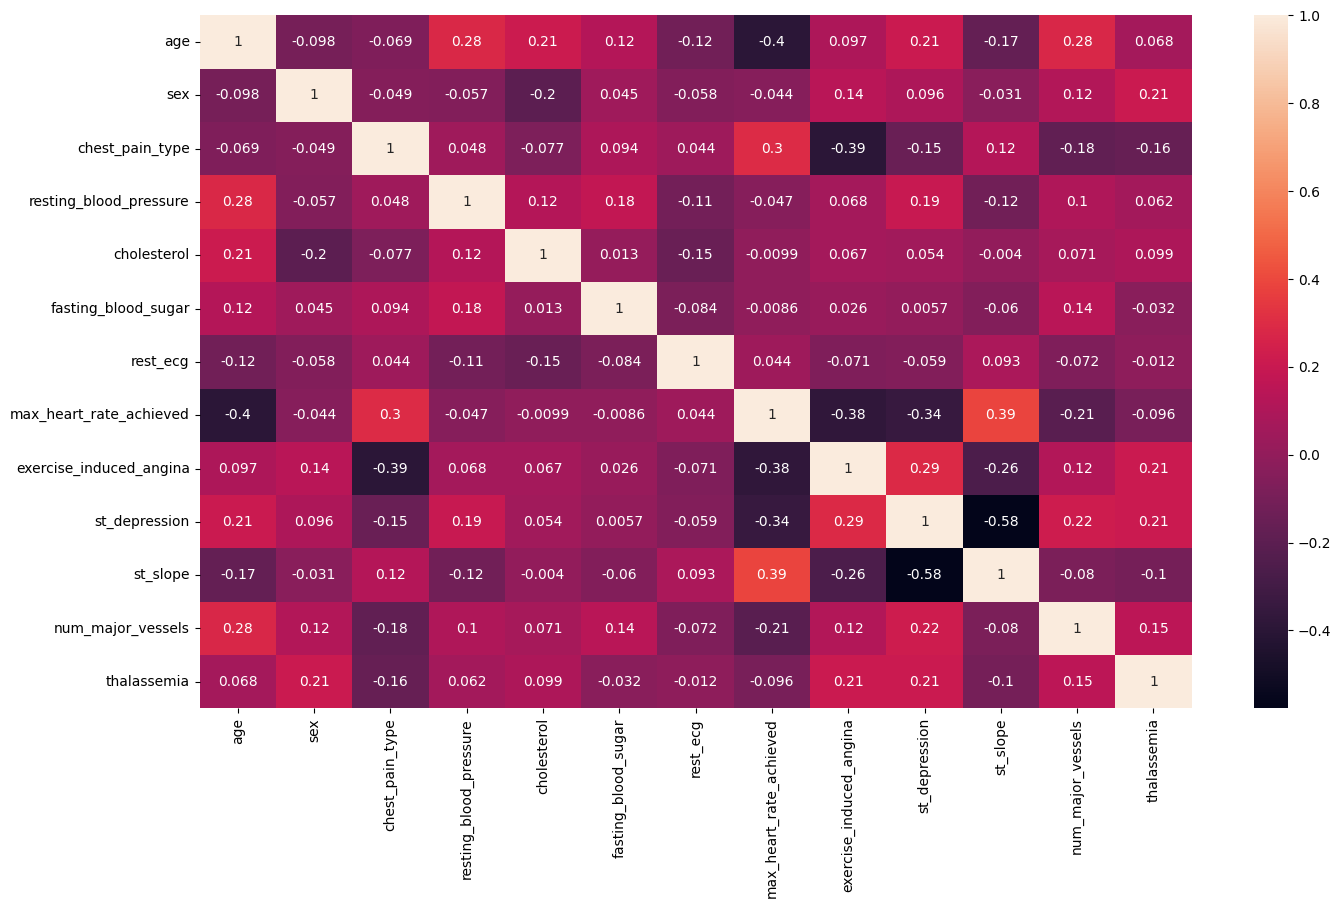

Các cột bị loại bỏ: []


In [3]:
print(HO_TEN, "-", MSSV)

cot_dac_trung = [c for c in data.columns if c != 'target']

plt.figure(figsize=(16, 9))
sns.heatmap(data[cot_dac_trung].corr(method='pearson'), annot=True)
plt.show()

# Loại bỏ các cột có độ tương đồng cao (|r| > 0.8)
corr = data[cot_dac_trung].corr(method='pearson').abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
cot_loai_bo = [c for c in upper.columns if (upper[c] > 0.8).any()]
print("Các cột bị loại bỏ:", cot_loai_bo)
data = data.drop(columns=cot_loai_bo)

## Câu 4: Tách các cột thành thuộc tính bình thường và thuộc tính quyết định

In [4]:
print(HO_TEN, "-", MSSV)

features = data.drop('target', axis=1)
labels = data['target']
print(features.shape, labels.shape)

Nguyễn Gia Huy - 6451071027
(303, 13) (303,)


## Câu 5: Chuyển các cột không phải dạng số về dạng one-hot vector

In [5]:
print(HO_TEN, "-", MSSV)

cot_khong_phai_so = features.select_dtypes(exclude=['number']).columns
print(cot_khong_phai_so)

features_onehot = pd.get_dummies(features, columns=cot_khong_phai_so)
features_onehot

Nguyễn Gia Huy - 6451071027
Index([], dtype='object')


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3


## Câu 6: Tách dữ liệu thành hai phần huấn luyện 70% và kiểm thử 30%

In [6]:
print(HO_TEN, "-", MSSV)

X, y = features_onehot, labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

Nguyễn Gia Huy - 6451071027
(212, 13) (91, 13) (212,) (91,)


## Câu 7: Xây dựng cây ID3, kiểm thử bằng ma trận nhầm lẫn, biểu diễn cây

In [7]:
print(HO_TEN, "-", MSSV)

clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
#Train Decision Tree Classifer
clf.fit(X_train, y_train)

Nguyễn Gia Huy - 6451071027


DecisionTreeClassifier(criterion='entropy', random_state=0)

In [8]:
print(HO_TEN, "-", MSSV)

#Predict the response for test dataset
tree_pred = clf.predict(X_test)

# Model Accuracy, how often is the classifier correct?
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:", metrics.classification_report(y_test, tree_pred, zero_division=0))

Nguyễn Gia Huy - 6451071027
Accuracy: 0.7252747252747253
Report:               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



Nguyễn Gia Huy - 6451071027


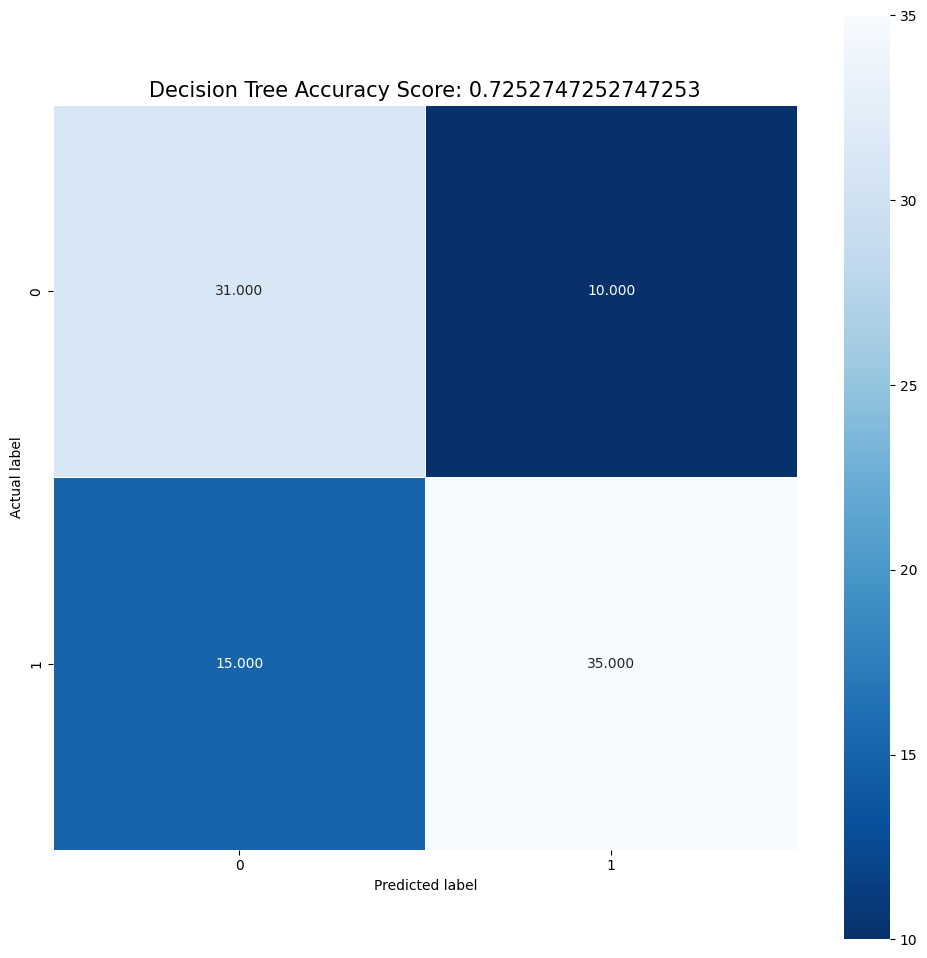

In [9]:
print(HO_TEN, "-", MSSV)

tree_cm = metrics.confusion_matrix(y_test, tree_pred)

plt.figure(figsize=(12,12))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf.classes_, yticklabels=clf.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree Accuracy Score: {0}'.format(tree_score)
plt.title(title, size=15);

Nguyễn Gia Huy - 6451071027


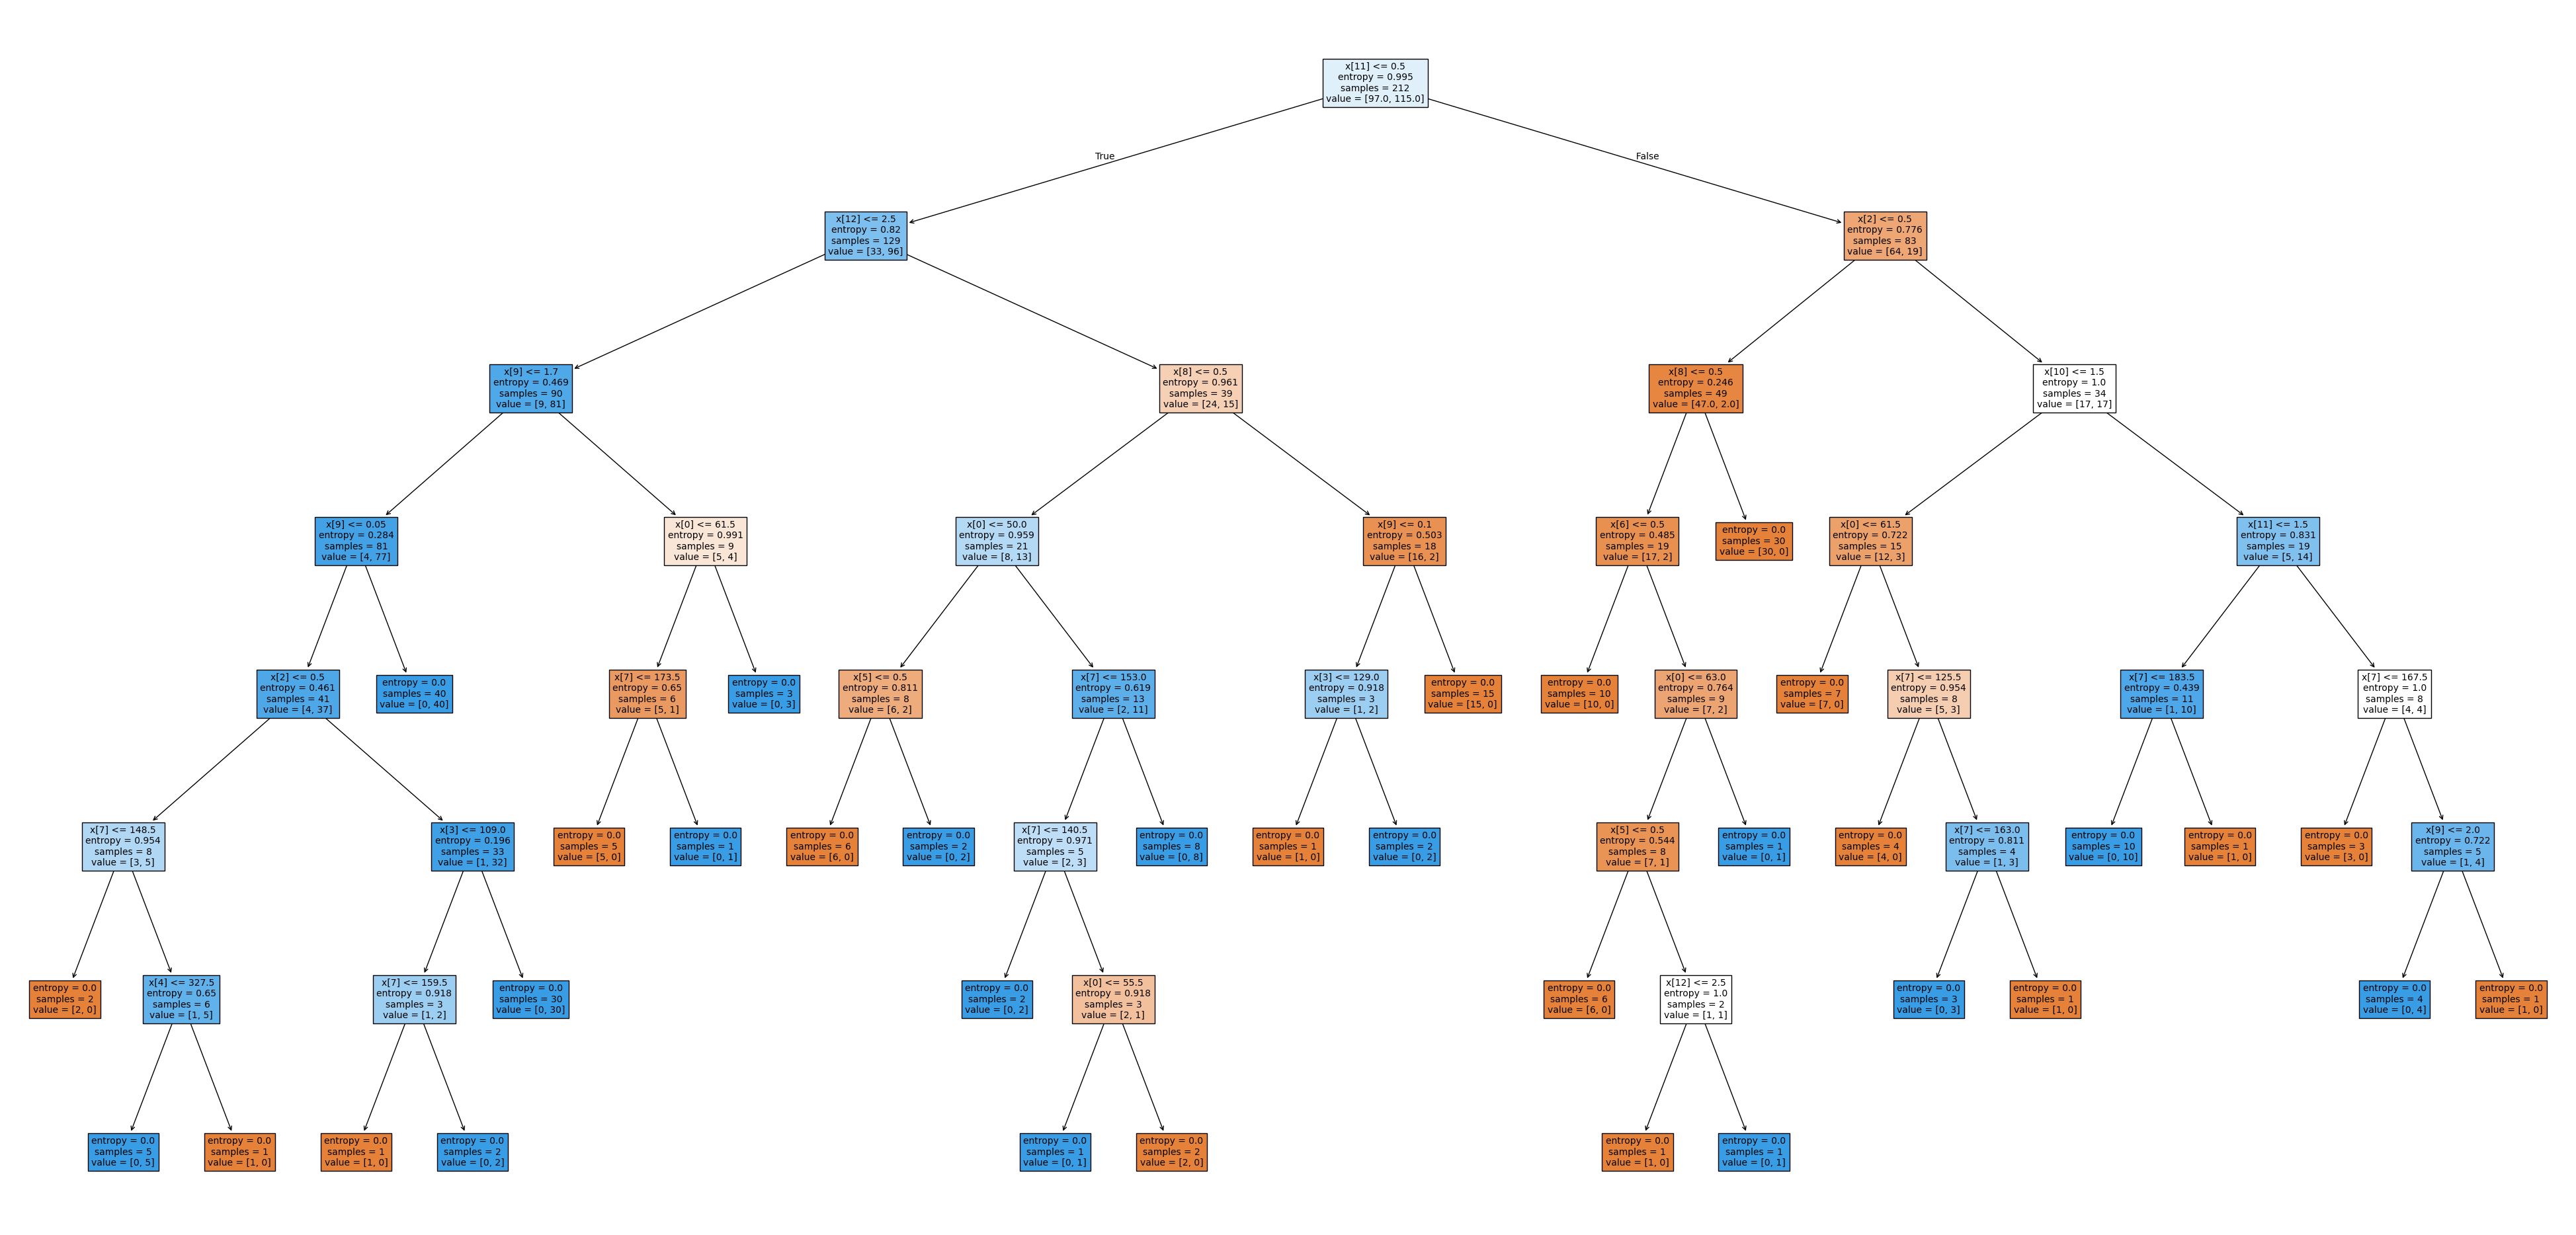

In [10]:
print(HO_TEN, "-", MSSV)

fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf, filled=True, fontsize=10)
plt.savefig('decision_tree', dpi=100)
plt.show()

## Câu 8: Xây dựng cây CART (criterion='gini')

In [11]:
print(HO_TEN, "-", MSSV)

clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
#Train Decision Tree Classifer
clf_cart.fit(X_train, y_train)

Nguyễn Gia Huy - 6451071027


DecisionTreeClassifier(random_state=0)

In [12]:
print(HO_TEN, "-", MSSV)

#Predict the response for test dataset
cart_pred = clf_cart.predict(X_test)

# Model Accuracy, how often is the classifier correct?
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:", metrics.classification_report(y_test, cart_pred, zero_division=0))

Nguyễn Gia Huy - 6451071027
Accuracy: 0.7252747252747253
Report:               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



Nguyễn Gia Huy - 6451071027


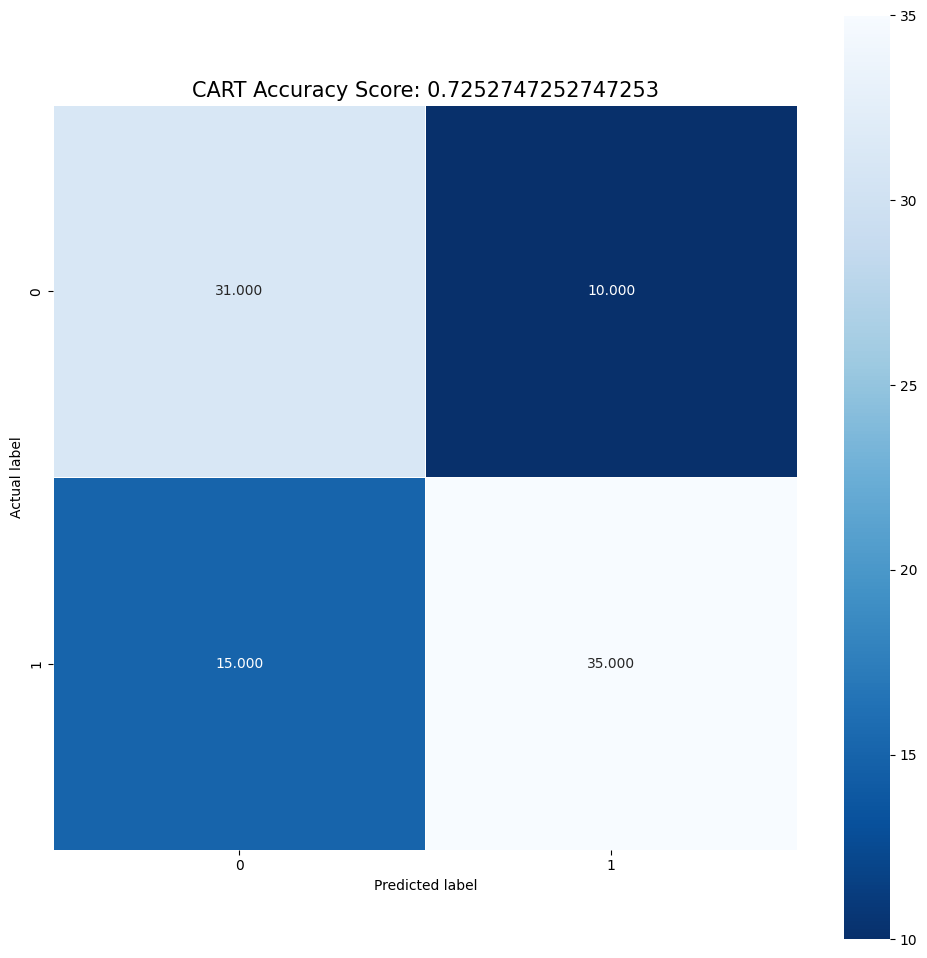

In [13]:
print(HO_TEN, "-", MSSV)

cart_cm = metrics.confusion_matrix(y_test, cart_pred)

plt.figure(figsize=(12,12))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'CART Accuracy Score: {0}'.format(cart_score)
plt.title(title, size=15);

Nguyễn Gia Huy - 6451071027


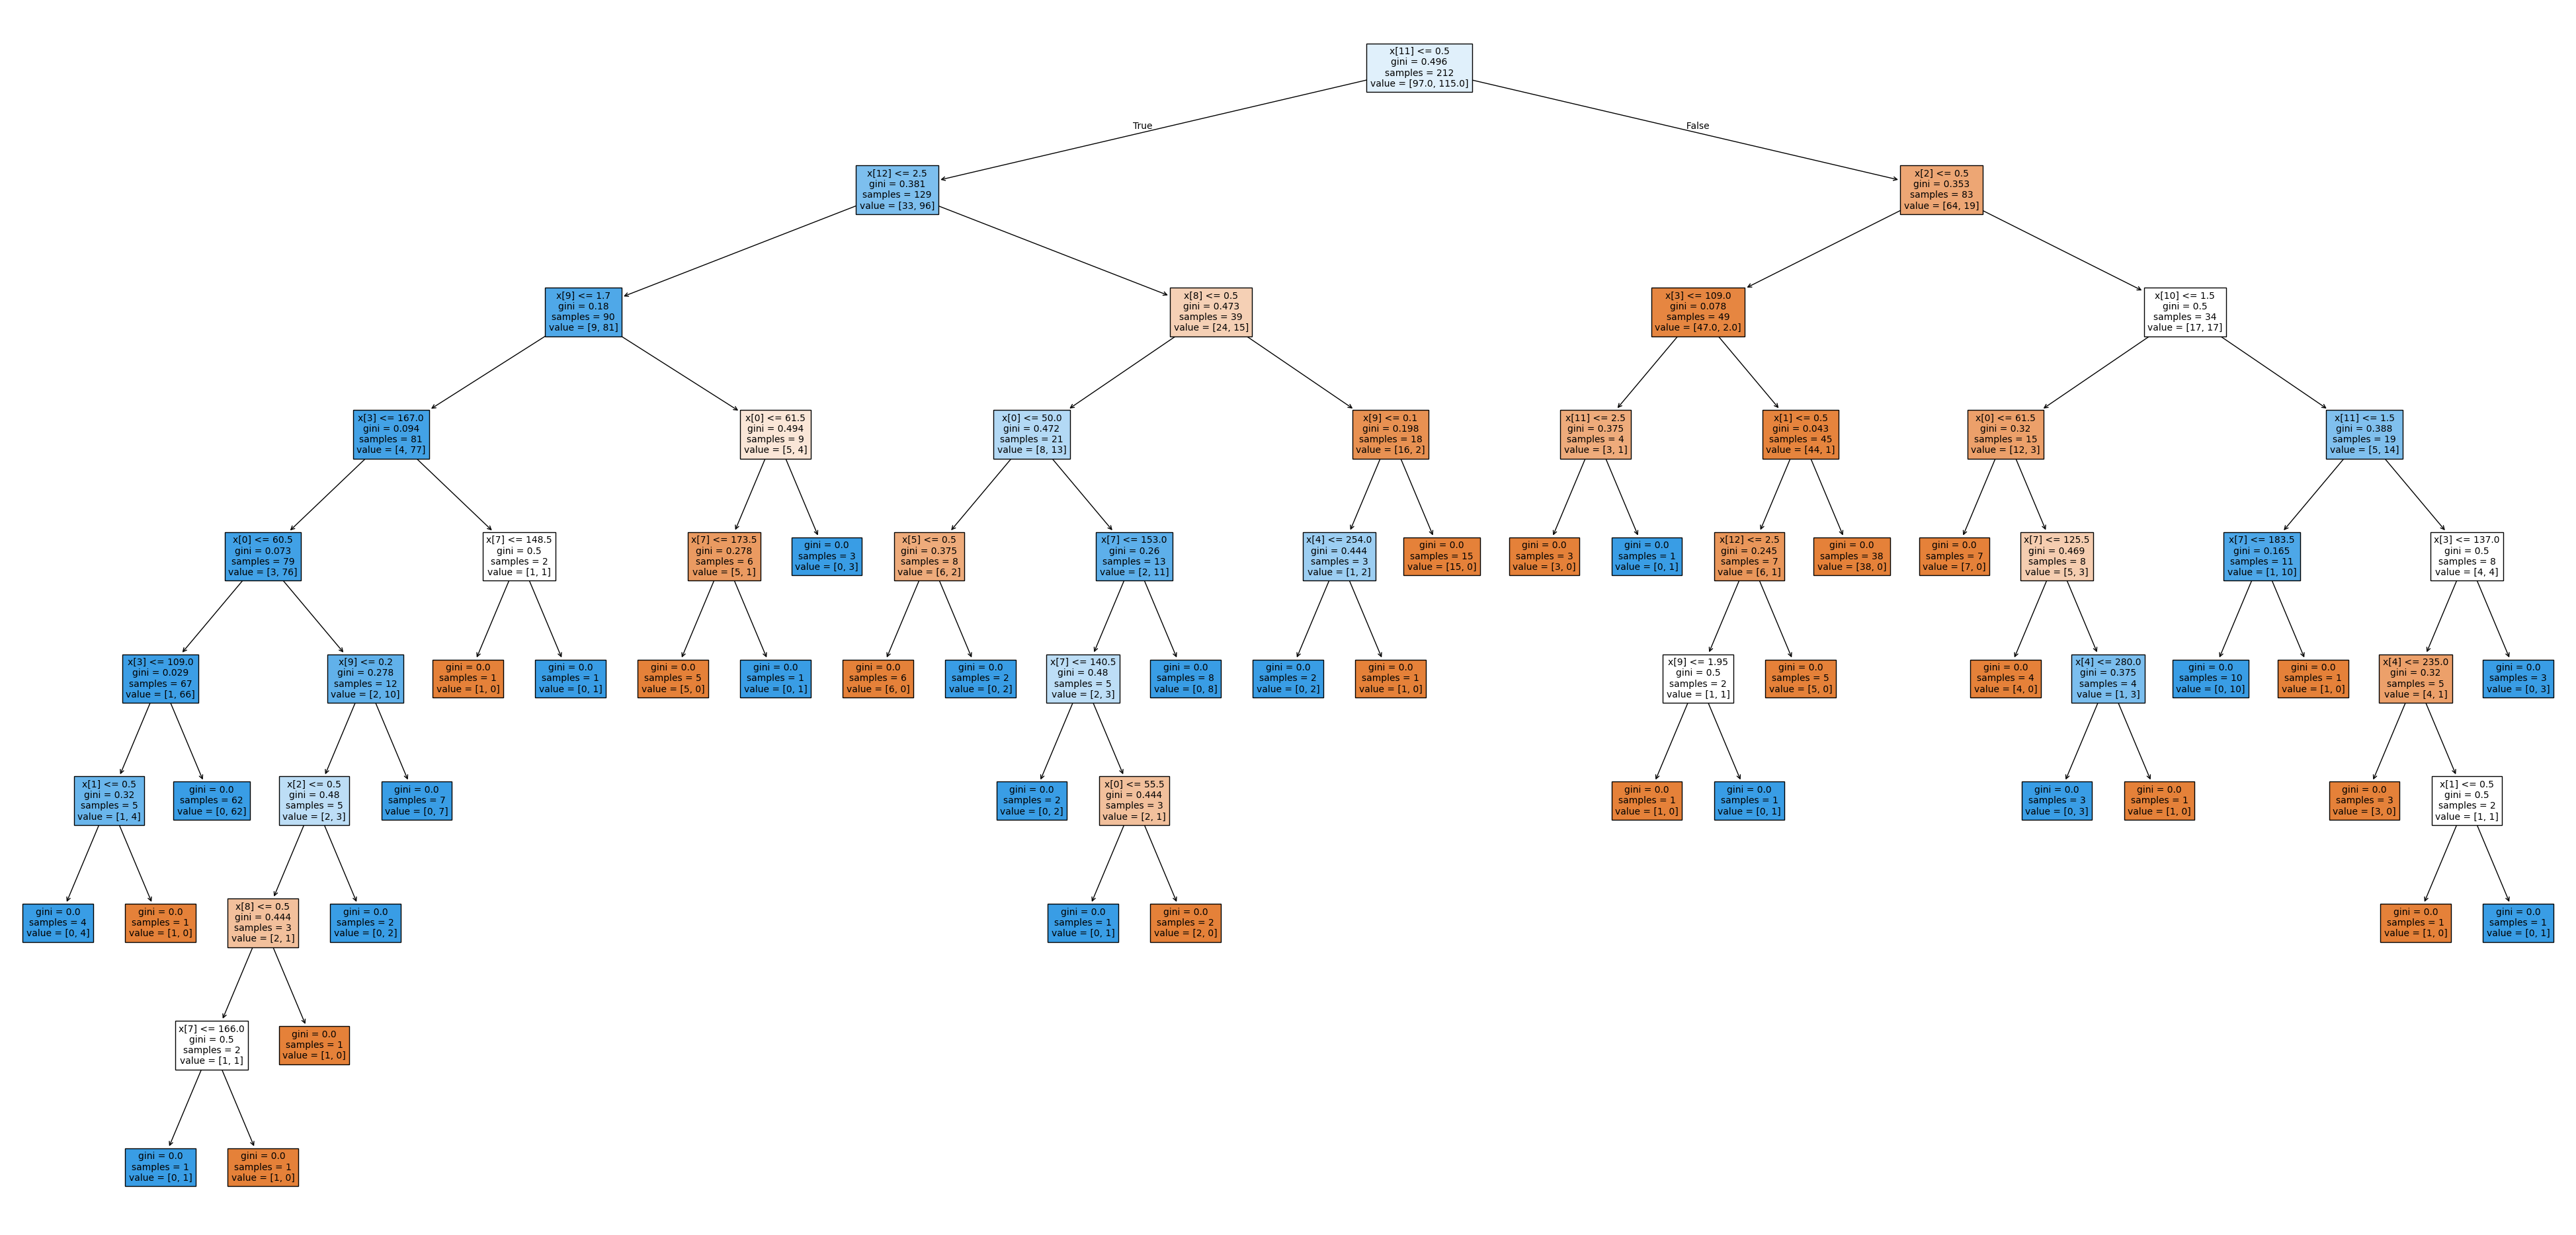

In [14]:
print(HO_TEN, "-", MSSV)

fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_cart, filled=True, fontsize=10)
plt.savefig('decision_tree_cart', dpi=100)
plt.show()

## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes

In [15]:
print(HO_TEN, "-", MSSV)

gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Nguyễn Gia Huy - 6451071027


In [16]:
print(HO_TEN, "-", MSSV)

# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred, zero_division=0))

Nguyễn Gia Huy - 6451071027
Accuracy: 0.8351648351648352
Report:               precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



Nguyễn Gia Huy - 6451071027


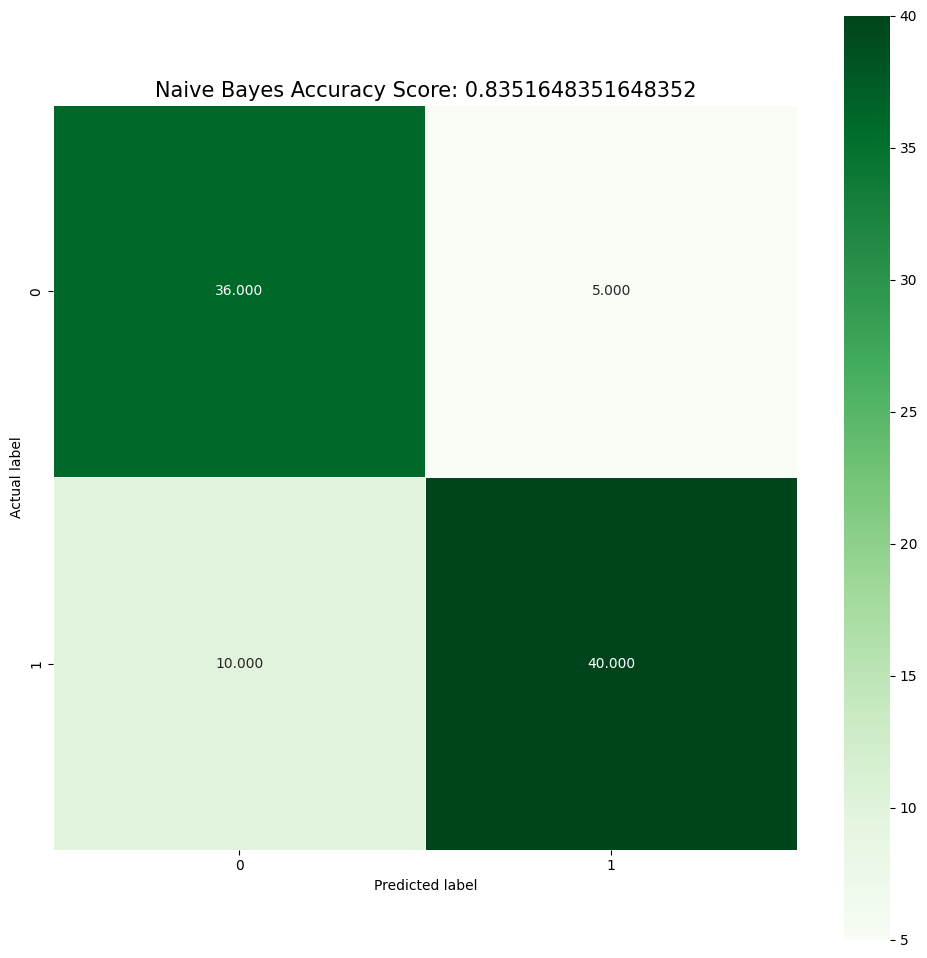

In [17]:
print(HO_TEN, "-", MSSV)

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

plt.figure(figsize=(12,12))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Naive Bayes Accuracy Score: {0}'.format(bayes_score)
plt.title(title, size=15);

## Câu 10: So sánh kết quả của các mô hình

In [18]:
print(HO_TEN, "-", MSSV)

ket_qua = {'ID3': tree_pred, 'CART': cart_pred, 'Naive Bayes': bayes_pred}
bang = pd.DataFrame({
    ten: {
        'Accuracy': metrics.accuracy_score(y_test, pred),
        'Precision (macro avg)': metrics.precision_score(y_test, pred, average='macro', zero_division=0),
        'Recall (macro avg)': metrics.recall_score(y_test, pred, average='macro', zero_division=0),
        'F1-score (macro avg)': metrics.f1_score(y_test, pred, average='macro', zero_division=0),
        'Precision (weighted avg)': metrics.precision_score(y_test, pred, average='weighted', zero_division=0),
        'Recall (weighted avg)': metrics.recall_score(y_test, pred, average='weighted', zero_division=0),
        'F1-score (weighted avg)': metrics.f1_score(y_test, pred, average='weighted', zero_division=0),
    } for ten, pred in ket_qua.items()
}).round(4)
bang

Nguyễn Gia Huy - 6451071027


,ID3,CART,Naive Bayes
Accuracy,0.7253,0.7253,0.8352
Precision (macro avg),0.7258,0.7258,0.8357
Recall (macro avg),0.7280,0.7280,0.8390
F1-score (macro avg),0.7247,0.7247,0.8348
Precision (weighted avg),0.7310,0.7310,0.8410
Recall (weighted avg),0.7253,0.7253,0.8352
F1-score (weighted avg),0.7259,0.7259,0.8356


Nguyễn Gia Huy - 6451071027


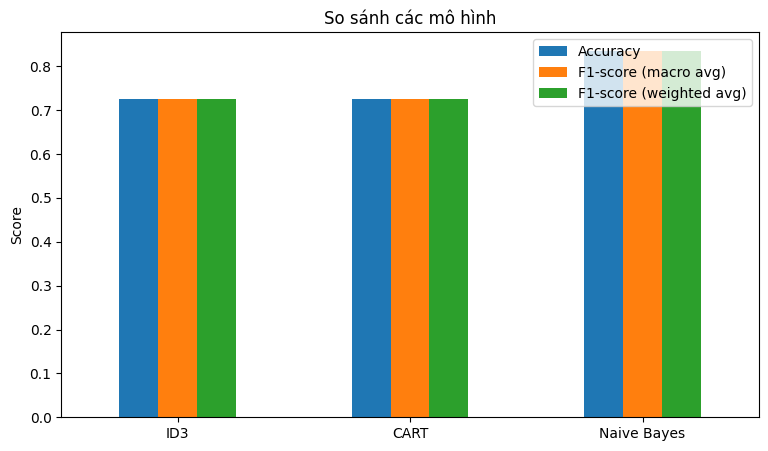

In [19]:
print(HO_TEN, "-", MSSV)

bang.T[['Accuracy', 'F1-score (macro avg)', 'F1-score (weighted avg)']].plot(kind='bar', figsize=(9, 5), rot=0)
plt.title('So sánh các mô hình')
plt.ylabel('Score')
plt.show()